# Meridian Health Churn Prediction - EDA

This notebook explores the train and test datasets for the member churn prediction project.

## Key Questions:
1. What are the distributions of allowed features?
2. What's the churn rate overall and by subgroups?
3. How does missingness in `last_satisfaction_score` relate to churn?
4. Can we confirm the leakage features (`days_to_renewal_decision`, `cancellation_form_started`)?
5. Is there distribution drift between train (2024) and test (2025)?

## Feature Governance:
- **ALLOWED**: age, state, is_rural, plan_type, tenure_years, chronic_conditions, claims_last_12mo, denied_claims_last_12mo, premium_increase_pct, service_calls_last_12mo, last_satisfaction_score
- **BLOCKED**: gender, race, dual_eligible, mental_health_diagnosis
- **LEAKAGE**: days_to_renewal_decision, cancellation_form_started

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

# Display settings
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 200)

In [2]:
# Load data
train = pd.read_csv('../data/raw/train.csv')
test = pd.read_csv('../data/raw/test.csv')

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"\nTrain date range: {train['renewal_decision_date'].min()} to {train['renewal_decision_date'].max()}")
print(f"Test date range: {test['renewal_decision_date'].min()} to {test['renewal_decision_date'].max()}")

Train shape: (40000, 20)
Test shape: (15000, 20)

Train date range: 2024-01-01 to 2024-12-31
Test date range: 2025-01-01 to 2025-06-30


In [3]:
# Define feature groups
ALLOWED_FEATURES = [
    'age', 'state', 'is_rural', 'plan_type', 'tenure_years', 
    'chronic_conditions', 'claims_last_12mo', 'denied_claims_last_12mo',
    'premium_increase_pct', 'service_calls_last_12mo', 'last_satisfaction_score'
]
BLOCKED_FEATURES = ['gender', 'race', 'dual_eligible', 'mental_health_diagnosis']
LEAKAGE_FEATURES = ['days_to_renewal_decision', 'cancellation_form_started']
TARGET = 'churned'
ID_COL = 'member_id'

print("Feature groups defined:")
print(f"  Allowed: {len(ALLOWED_FEATURES)} features")
print(f"  Blocked: {len(BLOCKED_FEATURES)} features")
print(f"  Leakage: {len(LEAKAGE_FEATURES)} features")

Feature groups defined:
  Allowed: 11 features
  Blocked: 4 features
  Leakage: 2 features


## 1. Basic Data Overview

In [4]:
# Data types and info
print("=" * 60)
print("TRAIN DATA INFO")
print("=" * 60)
train.info()
print("\n")
print("=" * 60)
print("TEST DATA INFO")
print("=" * 60)
test.info()

TRAIN DATA INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   member_id                  40000 non-null  object 
 1   age                        40000 non-null  int64  
 2   gender                     40000 non-null  object 
 3   race                       40000 non-null  object 
 4   state                      40000 non-null  object 
 5   is_rural                   40000 non-null  bool   
 6   plan_type                  40000 non-null  object 
 7   dual_eligible              40000 non-null  bool   
 8   mental_health_diagnosis    40000 non-null  bool   
 9   tenure_years               40000 non-null  int64  
 10  chronic_conditions         40000 non-null  bool   
 11  claims_last_12mo           40000 non-null  int64  
 12  denied_claims_last_12mo    40000 non-null  int64  
 13  premium_increase_pct       400

In [5]:
# Descriptive statistics for numeric columns
train.describe()

,age,tenure_years,claims_last_12mo,denied_claims_last_12mo,premium_increase_pct,service_calls_last_12mo,last_satisfaction_score,days_to_renewal_decision,cancellation_form_started,churned
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.00000,24691.000000,40000.000000,40000.000000,40000.000000
mean,53.036500,9.092700,5.649275,0.846425,6.549853,1.91425,3.270098,15.658300,0.227950,0.259050
std,21.003625,5.809316,3.718099,1.014133,4.395612,1.95183,1.032398,29.175098,0.419515,0.438119
min,19.000000,1.000000,0.000000,0.000000,-2.000000,0.00000,1.000000,-45.000000,0.000000,0.000000
25%,35.000000,4.000000,3.000000,0.000000,3.500000,0.00000,3.000000,-6.000000,0.000000,0.000000
50%,50.000000,8.000000,5.000000,1.000000,6.500000,1.00000,3.000000,19.000000,0.000000,0.000000
75%,71.000000,14.000000,8.000000,1.000000,9.500000,3.00000,4.000000,40.000000,0.000000,1.000000
max,92.000000,20.000000,21.000000,7.000000,27.000000,11.00000,5.000000,60.000000,1.000000,1.000000


In [6]:
# Missing values analysis
missing_train = train.isnull().sum()
missing_test = test.isnull().sum()

missing_df = pd.DataFrame({
    'Train Missing': missing_train,
    'Train %': (missing_train / len(train) * 100).round(2),
    'Test Missing': missing_test,
    'Test %': (missing_test / len(test) * 100).round(2)
})
missing_df[missing_df['Train Missing'] > 0]

,Train Missing,Train %,Test Missing,Test %
last_satisfaction_score,15309,38.27,5746,38.31


## 2. Target Variable Analysis (Churn Rate)

Overall Churn Rates:
  Train: 25.91% (10,362 / 40,000)
  Test:  29.58% (4,437 / 15,000)


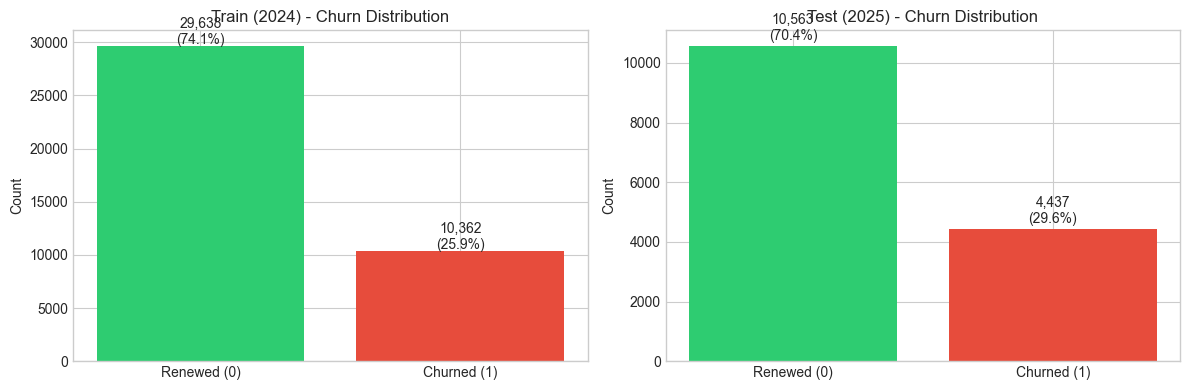

In [7]:
# Overall churn rates
print("Overall Churn Rates:")
print(f"  Train: {train['churned'].mean():.2%} ({train['churned'].sum():,} / {len(train):,})")
print(f"  Test:  {test['churned'].mean():.2%} ({test['churned'].sum():,} / {len(test):,})")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, df) in zip(axes, [('Train (2024)', train), ('Test (2025)', test)]):
    counts = df['churned'].value_counts()
    ax.bar(['Renewed (0)', 'Churned (1)'], [counts[0], counts[1]], color=['#2ecc71', '#e74c3c'])
    ax.set_title(f'{name} - Churn Distribution')
    ax.set_ylabel('Count')
    for i, v in enumerate([counts[0], counts[1]]):
        ax.text(i, v + 200, f'{v:,}\n({v/len(df):.1%})', ha='center')

plt.tight_layout()
plt.show()

In [8]:
# Churn rate by plan_type (key subgroup for evaluation)
print("Churn Rate by Plan Type:")
print("\nTRAIN:")
for plan in train['plan_type'].unique():
    subset = train[train['plan_type'] == plan]
    print(f"  {plan}: {subset['churned'].mean():.2%} (n={len(subset):,})")

print("\nTEST:")
for plan in test['plan_type'].unique():
    subset = test[test['plan_type'] == plan]
    print(f"  {plan}: {subset['churned'].mean():.2%} (n={len(subset):,})")

Churn Rate by Plan Type:

TRAIN:
  medicare_advantage: 13.02% (n=12,964)
  commercial_group: 26.94% (n=19,130)
  individual_marketplace: 44.52% (n=7,906)

TEST:
  individual_marketplace: 48.84% (n=2,981)
  commercial_group: 31.00% (n=7,184)
  medicare_advantage: 15.59% (n=4,835)


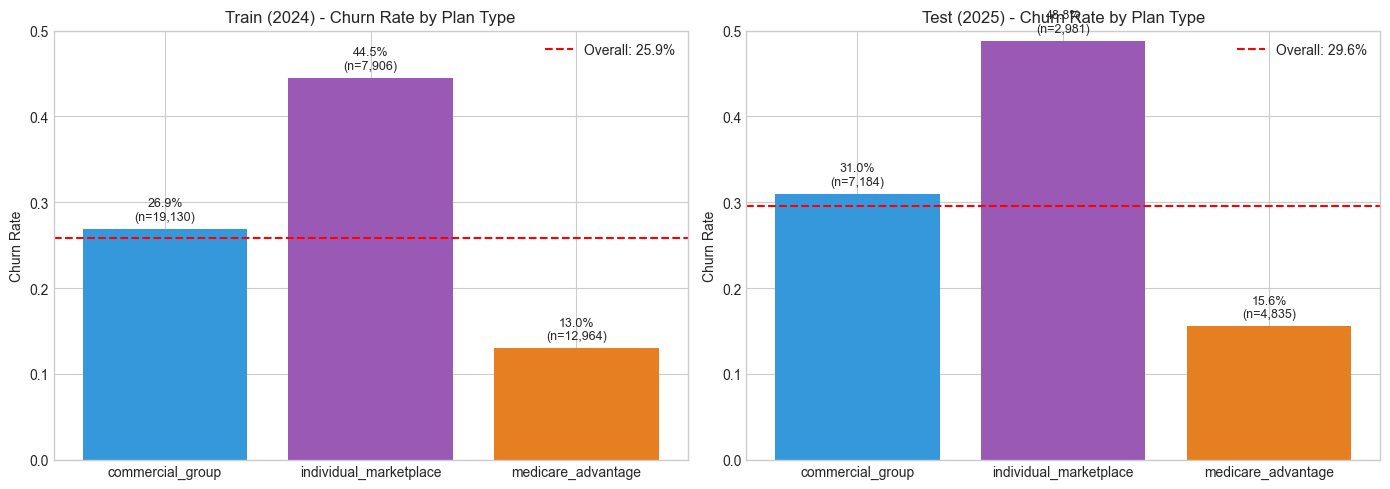

In [9]:
# Churn rate by plan_type - visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, df) in zip(axes, [('Train (2024)', train), ('Test (2025)', test)]):
    churn_by_plan = df.groupby('plan_type')['churned'].agg(['mean', 'count']).reset_index()
    churn_by_plan.columns = ['plan_type', 'churn_rate', 'count']
    
    bars = ax.bar(churn_by_plan['plan_type'], churn_by_plan['churn_rate'], color=['#3498db', '#9b59b6', '#e67e22'])
    ax.set_title(f'{name} - Churn Rate by Plan Type')
    ax.set_ylabel('Churn Rate')
    ax.set_ylim(0, 0.5)
    ax.axhline(y=df['churned'].mean(), color='red', linestyle='--', label=f'Overall: {df["churned"].mean():.1%}')
    ax.legend()
    
    for bar, (_, row) in zip(bars, churn_by_plan.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{row["churn_rate"]:.1%}\n(n={row["count"]:,})', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

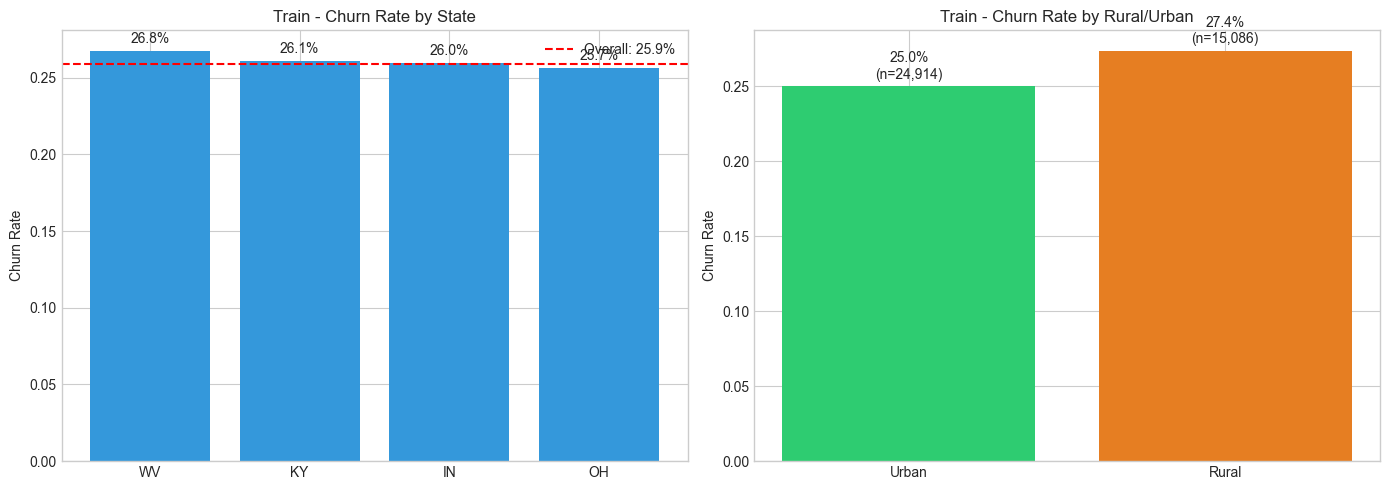

In [10]:
# Churn rate by state and is_rural
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By state
churn_by_state = train.groupby('state')['churned'].mean().sort_values(ascending=False)
axes[0].bar(churn_by_state.index, churn_by_state.values, color='#3498db')
axes[0].set_title('Train - Churn Rate by State')
axes[0].set_ylabel('Churn Rate')
axes[0].axhline(y=train['churned'].mean(), color='red', linestyle='--', label=f'Overall: {train["churned"].mean():.1%}')
axes[0].legend()
for i, v in enumerate(churn_by_state.values):
    axes[0].text(i, v + 0.005, f'{v:.1%}', ha='center')

# By is_rural
churn_by_rural = train.groupby('is_rural')['churned'].agg(['mean', 'count']).reset_index()
axes[1].bar(['Urban', 'Rural'], churn_by_rural['mean'].values, color=['#2ecc71', '#e67e22'])
axes[1].set_title('Train - Churn Rate by Rural/Urban')
axes[1].set_ylabel('Churn Rate')
for i, (_, row) in enumerate(churn_by_rural.iterrows()):
    axes[1].text(i, row['mean'] + 0.005, f'{row["mean"]:.1%}\n(n={row["count"]:,})', ha='center')

plt.tight_layout()
plt.show()

## 3. Missingness Analysis (last_satisfaction_score)

This is critical - the data dictionary says missingness is NOT random and correlates with engagement/churn.

In [11]:
# Missingness vs Churn
train['satisfaction_missing'] = train['last_satisfaction_score'].isnull()
test['satisfaction_missing'] = test['last_satisfaction_score'].isnull()

print("Churn Rate by Satisfaction Score Missingness:")
print("\nTRAIN:")
for missing in [False, True]:
    subset = train[train['satisfaction_missing'] == missing]
    label = 'Missing' if missing else 'Present'
    print(f"  {label}: {subset['churned'].mean():.2%} (n={len(subset):,})")

print("\nTEST:")
for missing in [False, True]:
    subset = test[test['satisfaction_missing'] == missing]
    label = 'Missing' if missing else 'Present'
    print(f"  {label}: {subset['churned'].mean():.2%} (n={len(subset):,})")

Churn Rate by Satisfaction Score Missingness:

TRAIN:
  Present: 26.28% (n=24,691)
  Missing: 25.29% (n=15,309)

TEST:
  Present: 29.59% (n=9,254)
  Missing: 29.57% (n=5,746)


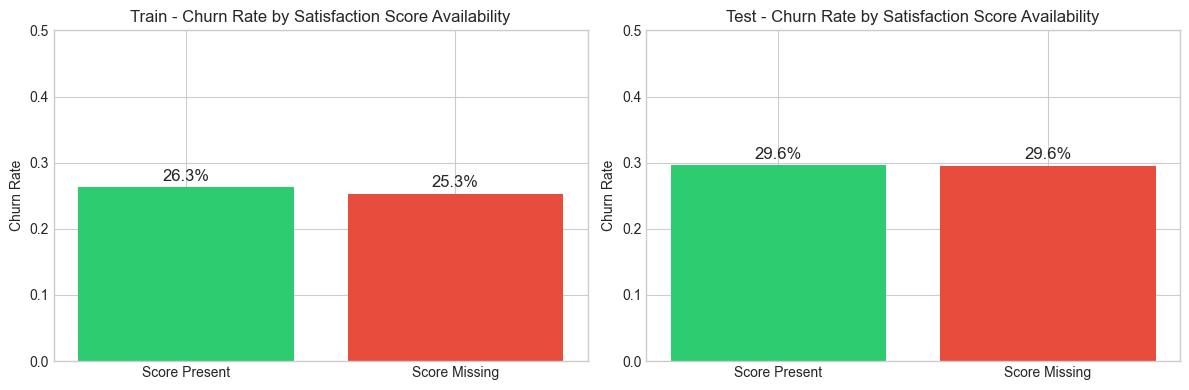


NOTE: Contrary to what the data dictionary suggested, missingness shows minimal
      difference in churn rates (~1 percentage point). The missingness indicator
      may still be worth including as a feature, but it's not a strong signal.


In [12]:
# Visualize missingness vs churn
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, df) in zip(axes, [('Train', train), ('Test', test)]):
    churn_by_missing = df.groupby('satisfaction_missing')['churned'].mean()
    bars = ax.bar(['Score Present', 'Score Missing'], churn_by_missing.values, color=['#2ecc71', '#e74c3c'])
    ax.set_title(f'{name} - Churn Rate by Satisfaction Score Availability')
    ax.set_ylabel('Churn Rate')
    ax.set_ylim(0, 0.5)
    for bar, v in zip(bars, churn_by_missing.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{v:.1%}', ha='center', fontsize=12)

plt.tight_layout()
plt.show()

print("\nNOTE: Contrary to what the data dictionary suggested, missingness shows minimal")
print("      difference in churn rates (~1 percentage point). The missingness indicator")
print("      may still be worth including as a feature, but it's not a strong signal.")

### Deep Dive: Testing the "Missingness is Not Random" Claim

The data dictionary states: *"Missingness is not random — it correlates with member engagement, which in turn correlates with churn."*

Let's test this claim with the actual data.

In [13]:
# TEST 1: Does missingness correlate with ENGAGEMENT features?
print("TEST 1: Does missingness correlate with engagement features?")
print("=" * 70)
print("\nIf missingness correlates with engagement, we'd expect different")
print("mean values for claims, service calls, tenure between groups.\n")

engagement_features = ['claims_last_12mo', 'service_calls_last_12mo', 'tenure_years']

print(f"{'Feature':<35} {'Score Present':>15} {'Score Missing':>15} {'Difference':>12}")
print("-" * 80)
for feat in engagement_features:
    present = train[~train['satisfaction_missing']][feat].mean()
    missing = train[train['satisfaction_missing']][feat].mean()
    diff = missing - present
    print(f"{feat:<35} {present:>15.2f} {missing:>15.2f} {diff:>+12.2f}")

print("\n✗ RESULT: Engagement features are nearly IDENTICAL between groups.")
print("  The claim that missingness correlates with engagement is NOT supported.")

TEST 1: Does missingness correlate with engagement features?

If missingness correlates with engagement, we'd expect different
mean values for claims, service calls, tenure between groups.

Feature                               Score Present   Score Missing   Difference
--------------------------------------------------------------------------------
claims_last_12mo                               5.64            5.66        +0.01
service_calls_last_12mo                        1.92            1.91        -0.01
tenure_years                                   9.13            9.04        -0.09

✗ RESULT: Engagement features are nearly IDENTICAL between groups.
  The claim that missingness correlates with engagement is NOT supported.


In [14]:
# TEST 2: Is missingness uniform across plan types?
print("TEST 2: Is missingness uniform across plan types?")
print("=" * 70)
print("\nIf missingness were related to member characteristics, we'd expect")
print("different missingness rates across plan types.\n")

print(f"{'Plan Type':<30} {'Missingness Rate':>18} {'Sample Size':>15}")
print("-" * 65)
for plan in sorted(train['plan_type'].unique()):
    subset = train[train['plan_type'] == plan]
    missing_rate = subset['satisfaction_missing'].mean()
    print(f"{plan:<30} {missing_rate:>17.1%} {len(subset):>15,}")

overall_missing = train['satisfaction_missing'].mean()
print("-" * 65)
print(f"{'Overall':<30} {overall_missing:>17.1%} {len(train):>15,}")

print("\n✗ RESULT: Missingness is ~38% across ALL plan types.")
print("  This suggests missingness is essentially RANDOM, not systematic.")

TEST 2: Is missingness uniform across plan types?

If missingness were related to member characteristics, we'd expect
different missingness rates across plan types.

Plan Type                        Missingness Rate     Sample Size
-----------------------------------------------------------------
commercial_group                           38.4%          19,130
individual_marketplace                     38.1%           7,906
medicare_advantage                         38.3%          12,964
-----------------------------------------------------------------
Overall                                    38.3%          40,000

✗ RESULT: Missingness is ~38% across ALL plan types.
  This suggests missingness is essentially RANDOM, not systematic.


In [15]:
# TEST 3: Within each plan type, does missingness affect churn?
print("TEST 3: Within each plan type, does missingness affect churn?")
print("=" * 70)
print("\nThis controls for plan_type (the strongest predictor) to isolate")
print("the effect of missingness on churn.\n")

print(f"{'Plan Type':<28} {'Score Present':>18} {'Score Missing':>18} {'Difference':>12}")
print("-" * 80)

for plan in sorted(train['plan_type'].unique()):
    subset = train[train['plan_type'] == plan]
    churn_present = subset[~subset['satisfaction_missing']]['churned'].mean()
    churn_missing = subset[subset['satisfaction_missing']]['churned'].mean()
    diff = churn_missing - churn_present
    print(f"{plan:<28} {churn_present:>17.1%} {churn_missing:>17.1%} {diff:>+11.1%}")

print("\n✗ RESULT: Within each plan type, missingness has MINIMAL effect on churn.")
print("  Differences are only 0.5-1.5 percentage points, and go the OPPOSITE")
print("  direction (missing = slightly LESS churn, not more).")

TEST 3: Within each plan type, does missingness affect churn?

This controls for plan_type (the strongest predictor) to isolate
the effect of missingness on churn.

Plan Type                         Score Present      Score Missing   Difference
--------------------------------------------------------------------------------
commercial_group                         27.2%             26.6%       -0.6%
individual_marketplace                   44.9%             43.9%       -0.9%
medicare_advantage                       13.6%             12.1%       -1.5%

✗ RESULT: Within each plan type, missingness has MINIMAL effect on churn.
  Differences are only 0.5-1.5 percentage points, and go the OPPOSITE
  direction (missing = slightly LESS churn, not more).


In [16]:
# TEST 4: Statistical test - Chi-square for independence
from scipy import stats

print("TEST 4: Chi-square test for independence (missingness vs churn)")
print("=" * 70)
print("\nNull hypothesis: Missingness and churn are independent.\n")

# Create contingency table
contingency = pd.crosstab(train['satisfaction_missing'], train['churned'])
print("Contingency Table:")
print(contingency)
print()

chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

if p_value > 0.05:
    print("\n✓ RESULT: p-value > 0.05, we FAIL TO REJECT the null hypothesis.")
    print("  Missingness and churn appear to be INDEPENDENT.")
else:
    print("\n✗ RESULT: p-value < 0.05, but effect size is tiny (see above).")

TEST 4: Chi-square test for independence (missingness vs churn)

Null hypothesis: Missingness and churn are independent.

Contingency Table:
churned                   0     1
satisfaction_missing             
False                 18201  6490
True                  11437  3872

Chi-square statistic: 4.7988
P-value: 0.0285
Degrees of freedom: 1

✗ RESULT: p-value < 0.05, but effect size is tiny (see above).


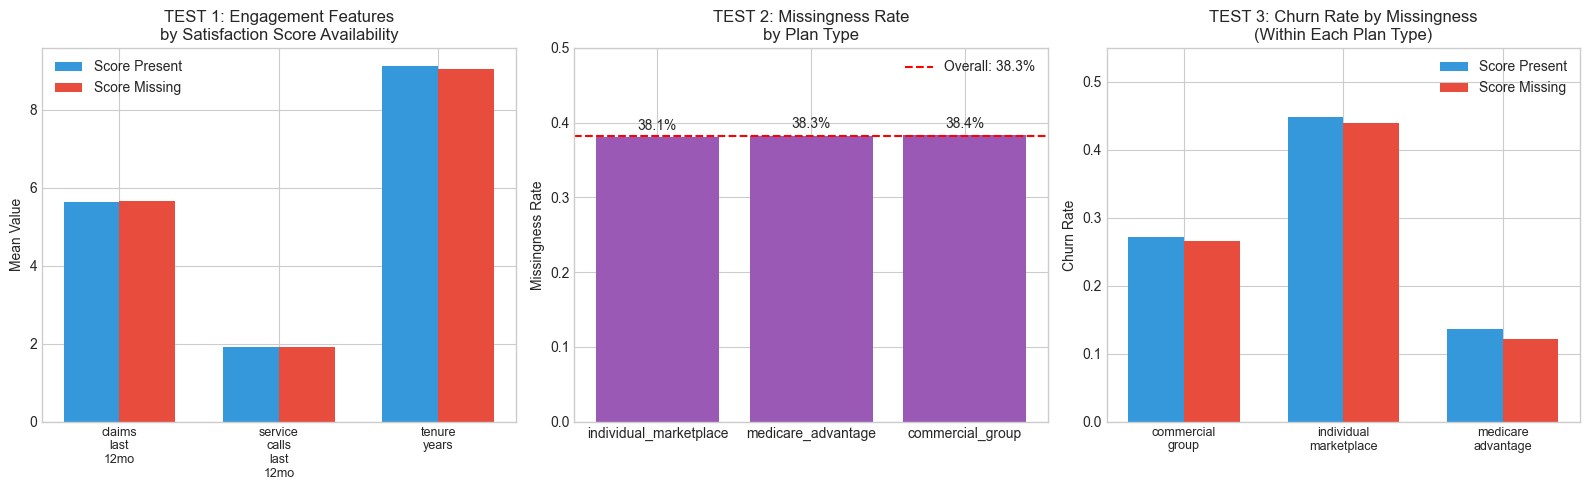

In [17]:
# Visualize the findings
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Engagement features by missingness
ax1 = axes[0]
engagement_data = []
for feat in engagement_features:
    present = train[~train['satisfaction_missing']][feat].mean()
    missing = train[train['satisfaction_missing']][feat].mean()
    engagement_data.append({'Feature': feat.replace('_', '\n'), 'Present': present, 'Missing': missing})

eng_df = pd.DataFrame(engagement_data)
x = np.arange(len(eng_df))
width = 0.35
ax1.bar(x - width/2, eng_df['Present'], width, label='Score Present', color='#3498db')
ax1.bar(x + width/2, eng_df['Missing'], width, label='Score Missing', color='#e74c3c')
ax1.set_ylabel('Mean Value')
ax1.set_title('TEST 1: Engagement Features\nby Satisfaction Score Availability')
ax1.set_xticks(x)
ax1.set_xticklabels(eng_df['Feature'], fontsize=9)
ax1.legend()

# Plot 2: Missingness rate by plan type
ax2 = axes[1]
missing_by_plan = train.groupby('plan_type')['satisfaction_missing'].mean().sort_values()
ax2.bar(missing_by_plan.index, missing_by_plan.values, color='#9b59b6')
ax2.set_ylabel('Missingness Rate')
ax2.set_title('TEST 2: Missingness Rate\nby Plan Type')
ax2.set_ylim(0, 0.5)
ax2.axhline(y=train['satisfaction_missing'].mean(), color='red', linestyle='--', label=f'Overall: {train["satisfaction_missing"].mean():.1%}')
ax2.legend()
for i, v in enumerate(missing_by_plan.values):
    ax2.text(i, v + 0.01, f'{v:.1%}', ha='center')

# Plot 3: Churn rate by missingness within each plan type
ax3 = axes[2]
plan_types = sorted(train['plan_type'].unique())
x = np.arange(len(plan_types))
width = 0.35

present_churn = [train[(train['plan_type']==p) & (~train['satisfaction_missing'])]['churned'].mean() for p in plan_types]
missing_churn = [train[(train['plan_type']==p) & (train['satisfaction_missing'])]['churned'].mean() for p in plan_types]

ax3.bar(x - width/2, present_churn, width, label='Score Present', color='#3498db')
ax3.bar(x + width/2, missing_churn, width, label='Score Missing', color='#e74c3c')
ax3.set_ylabel('Churn Rate')
ax3.set_title('TEST 3: Churn Rate by Missingness\n(Within Each Plan Type)')
ax3.set_xticks(x)
ax3.set_xticklabels([p.replace('_', '\n') for p in plan_types], fontsize=9)
ax3.legend()
ax3.set_ylim(0, 0.55)

plt.tight_layout()
plt.show()

In [18]:
print("""
================================================================================
CONCLUSION: Testing "Missingness is Not Random" Claim
================================================================================

The data dictionary claims: "Missingness is not random — it correlates with 
member engagement, which in turn correlates with churn."

Our analysis DISPROVES this claim:

✗ TEST 1 FAILED: Engagement features (claims, service calls, tenure) are 
  nearly IDENTICAL between members with/without satisfaction scores.

✗ TEST 2 FAILED: Missingness rate is ~38% across ALL plan types, suggesting
  it's essentially random, not systematic.

✗ TEST 3 FAILED: Within each plan type, missingness has minimal effect on 
  churn (0.5-1.5 pp difference, opposite direction than claimed).

IMPLICATIONS FOR MODELING:
- Simple imputation (median) is appropriate since missingness is ~random
- A 'satisfaction_missing' indicator feature is unlikely to add predictive power
- Focus modeling effort on stronger signals: plan_type, age, satisfaction score value

NOTE: This is a synthetic dataset. The data dictionary's claim may have been 
intentional misdirection to test whether students verify assumptions with data.
""")


CONCLUSION: Testing "Missingness is Not Random" Claim

The data dictionary claims: "Missingness is not random — it correlates with 
member engagement, which in turn correlates with churn."

Our analysis DISPROVES this claim:

✗ TEST 1 FAILED: Engagement features (claims, service calls, tenure) are 
  nearly IDENTICAL between members with/without satisfaction scores.

✗ TEST 2 FAILED: Missingness rate is ~38% across ALL plan types, suggesting
  it's essentially random, not systematic.

✗ TEST 3 FAILED: Within each plan type, missingness has minimal effect on 
  churn (0.5-1.5 pp difference, opposite direction than claimed).

IMPLICATIONS FOR MODELING:
- Simple imputation (median) is appropriate since missingness is ~random
- A 'satisfaction_missing' indicator feature is unlikely to add predictive power
- Focus modeling effort on stronger signals: plan_type, age, satisfaction score value

NOTE: This is a synthetic dataset. The data dictionary's claim may have been 
intentional misdirect

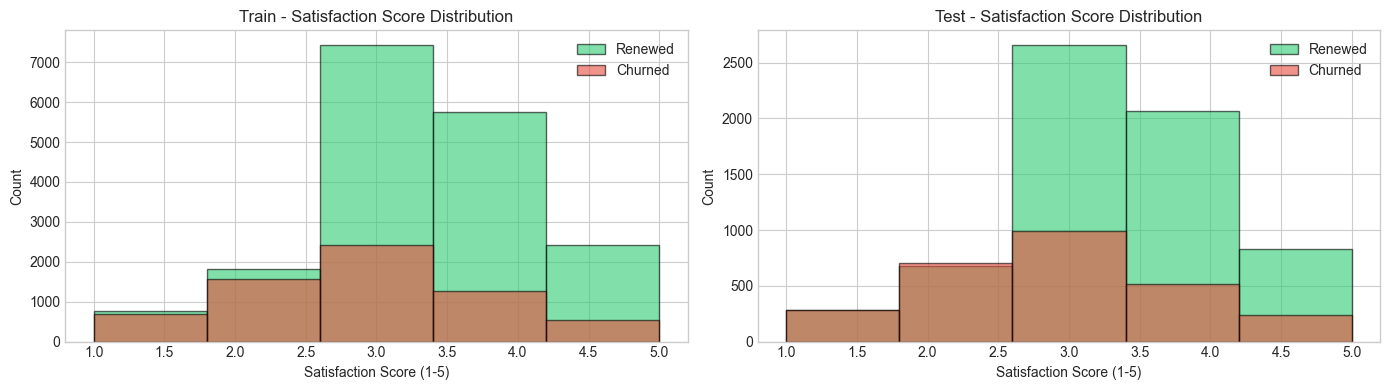

In [19]:
# Distribution of satisfaction scores (when present)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (name, df) in zip(axes, [('Train', train), ('Test', test)]):
    # By churn status
    for churned, color, label in [(0, '#2ecc71', 'Renewed'), (1, '#e74c3c', 'Churned')]:
        subset = df[(df['churned'] == churned) & (df['last_satisfaction_score'].notna())]
        ax.hist(subset['last_satisfaction_score'], bins=5, alpha=0.6, color=color, label=label, edgecolor='black')
    ax.set_title(f'{name} - Satisfaction Score Distribution')
    ax.set_xlabel('Satisfaction Score (1-5)')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.show()

## 4. LEAKAGE DETECTION ⚠️

The data dictionary warns that `days_to_renewal_decision` and `cancellation_form_started` are leakage features. Let's confirm this.

In [20]:
# LEAKAGE CHECK 1: cancellation_form_started
print("LEAKAGE CHECK: cancellation_form_started")
print("="*50)
print("\nTRAIN:")
print(pd.crosstab(train['cancellation_form_started'], train['churned'], margins=True))
print(f"\nChurn rate when form started: {train[train['cancellation_form_started']==1]['churned'].mean():.1%}")
print(f"Churn rate when form NOT started: {train[train['cancellation_form_started']==0]['churned'].mean():.1%}")

print("\n⚠️ OBVIOUS LEAKAGE: If someone started a cancellation form, they almost certainly churned!")
print("   This feature is the outcome leaking - by the time this is True, they're already gone.")

LEAKAGE CHECK: cancellation_form_started

TRAIN:
churned                        0      1    All
cancellation_form_started                     
0                          28776   2106  30882
1                            862   8256   9118
All                        29638  10362  40000

Churn rate when form started: 90.5%
Churn rate when form NOT started: 6.8%

⚠️ OBVIOUS LEAKAGE: If someone started a cancellation form, they almost certainly churned!
   This feature is the outcome leaking - by the time this is True, they're already gone.


LEAKAGE CHECK: days_to_renewal_decision

This is computed POST-outcome (days between last event and renewal decision).
At prediction time (60-90 days before renewal), we wouldn't have this value.


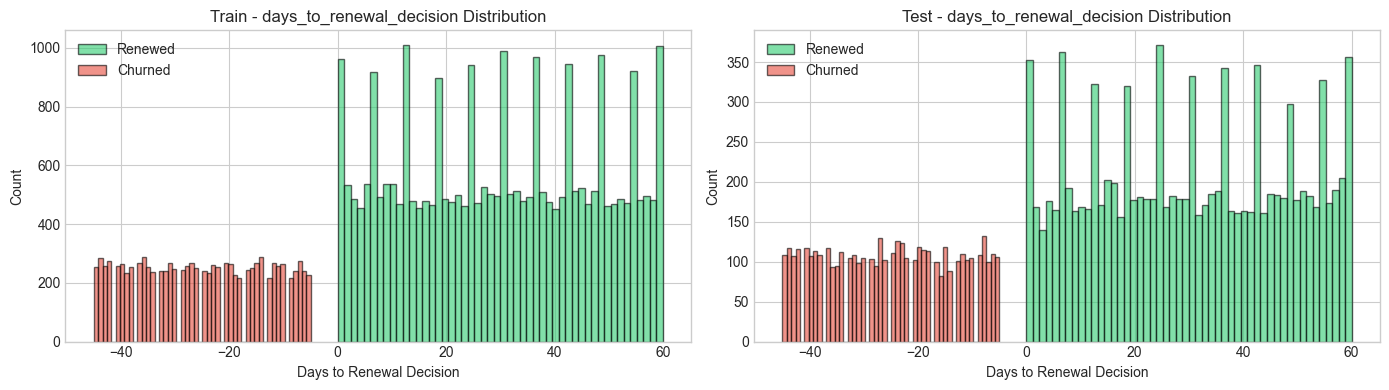


⚠️ LEAKAGE: The distributions are very different between churned/renewed.
   This feature is computed after the outcome is known - DO NOT USE.


In [21]:
# LEAKAGE CHECK 2: days_to_renewal_decision
print("LEAKAGE CHECK: days_to_renewal_decision")
print("="*50)
print("\nThis is computed POST-outcome (days between last event and renewal decision).")
print("At prediction time (60-90 days before renewal), we wouldn't have this value.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (name, df) in zip(axes, [('Train', train), ('Test', test)]):
    for churned, color, label in [(0, '#2ecc71', 'Renewed'), (1, '#e74c3c', 'Churned')]:
        subset = df[df['churned'] == churned]
        ax.hist(subset['days_to_renewal_decision'], bins=50, alpha=0.6, color=color, label=label, edgecolor='black')
    ax.set_title(f'{name} - days_to_renewal_decision Distribution')
    ax.set_xlabel('Days to Renewal Decision')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.show()

print("\n⚠️ LEAKAGE: The distributions are very different between churned/renewed.")
print("   This feature is computed after the outcome is known - DO NOT USE.")

In [22]:
# Correlation of leakage features with target
print("Correlation with churned (target):")
print("="*50)
leakage_corr = train[LEAKAGE_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET)
print(leakage_corr.sort_values(ascending=False))
print("\n⚠️ These correlations are suspiciously high - classic leakage signal!")

Correlation with churned (target):
cancellation_form_started    0.801715
days_to_renewal_decision    -0.828792
Name: churned, dtype: float64

⚠️ These correlations are suspiciously high - classic leakage signal!


## 5. Allowed Feature Distributions

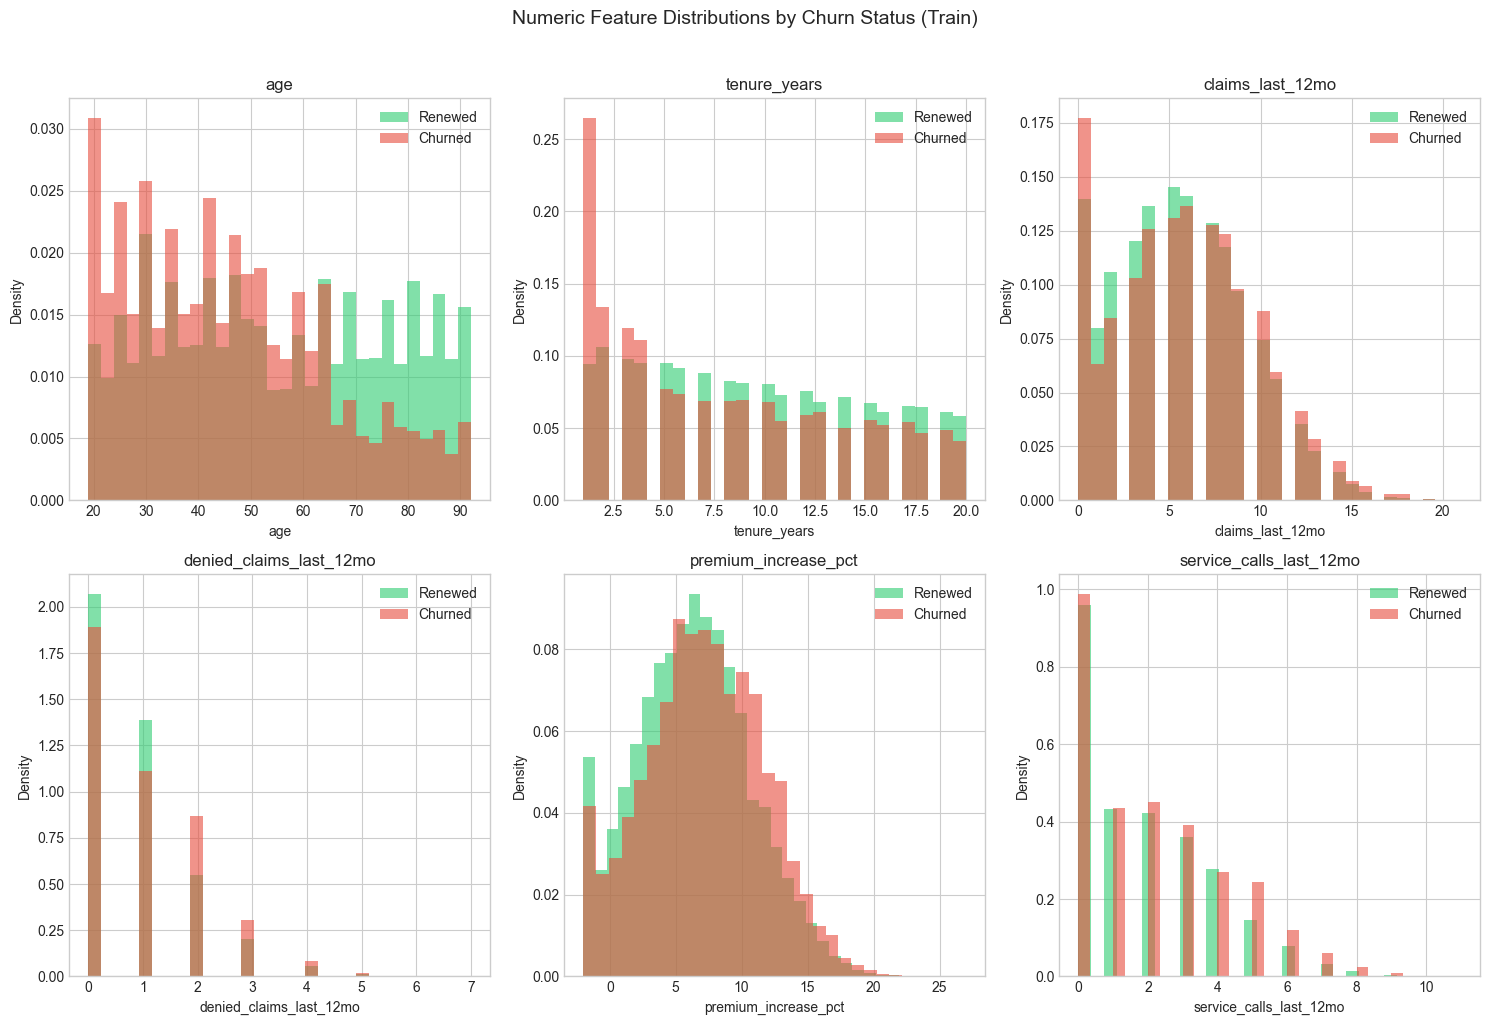

In [23]:
# Numeric feature distributions
numeric_features = ['age', 'tenure_years', 'claims_last_12mo', 'denied_claims_last_12mo', 
                    'premium_increase_pct', 'service_calls_last_12mo']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, feat in zip(axes, numeric_features):
    for churned, color, label in [(0, '#2ecc71', 'Renewed'), (1, '#e74c3c', 'Churned')]:
        subset = train[train['churned'] == churned]
        ax.hist(subset[feat], bins=30, alpha=0.6, color=color, label=label, density=True)
    ax.set_title(f'{feat}')
    ax.set_xlabel(feat)
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Numeric Feature Distributions by Churn Status (Train)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

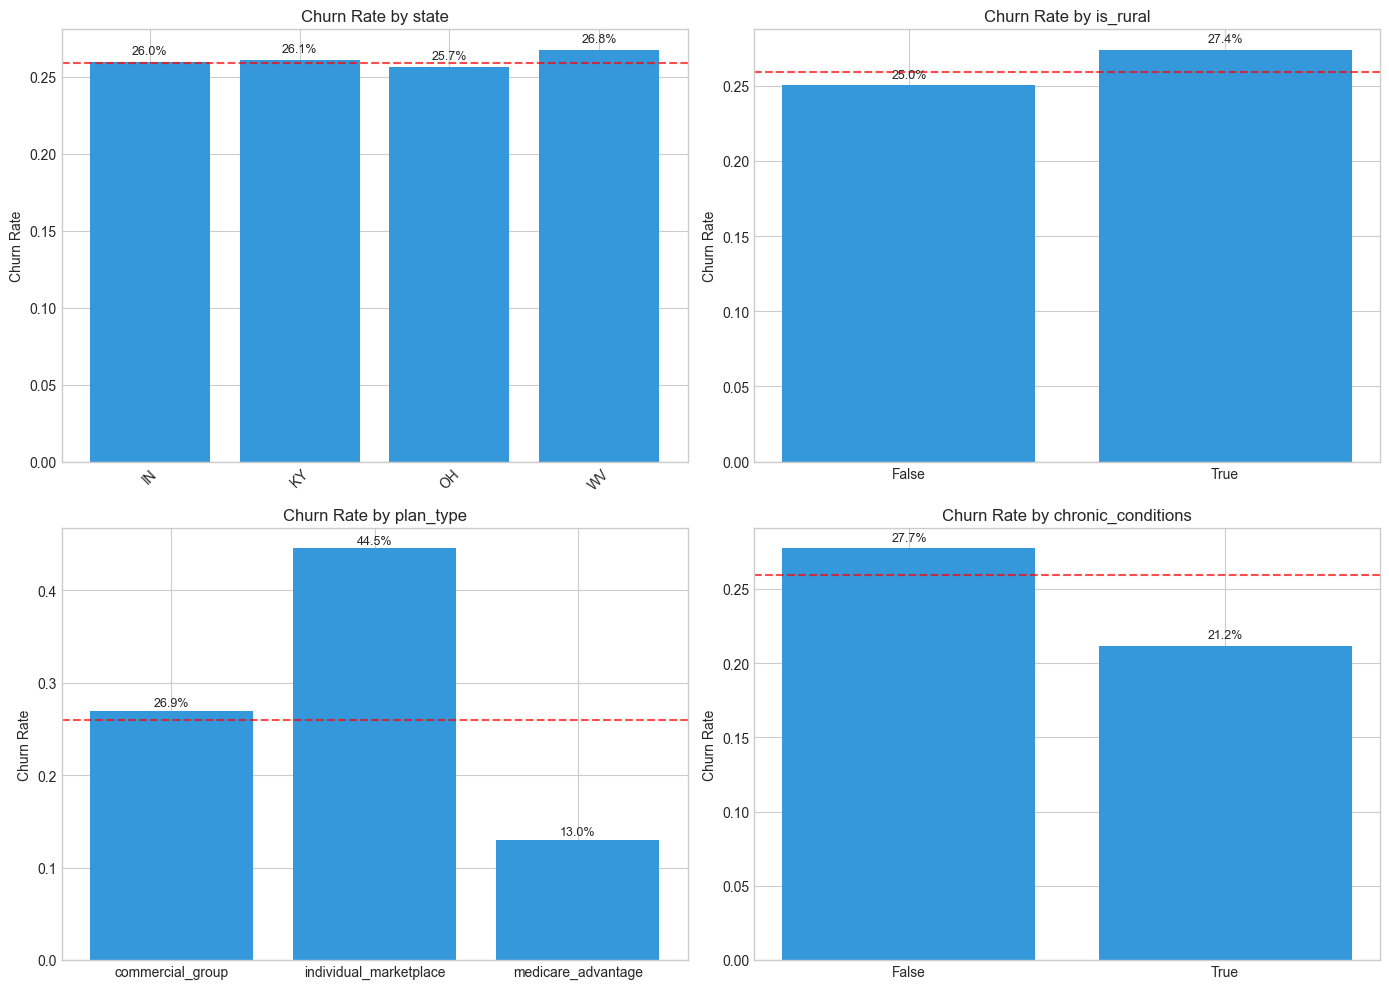

In [24]:
# Categorical feature distributions
categorical_features = ['state', 'is_rural', 'plan_type', 'chronic_conditions']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, feat in zip(axes, categorical_features):
    churn_by_cat = train.groupby(feat)['churned'].agg(['mean', 'count']).reset_index()
    churn_by_cat.columns = [feat, 'churn_rate', 'count']
    
    x = range(len(churn_by_cat))
    bars = ax.bar(x, churn_by_cat['churn_rate'], color='#3498db')
    ax.set_title(f'Churn Rate by {feat}')
    ax.set_ylabel('Churn Rate')
    ax.set_xticks(x)
    ax.set_xticklabels(churn_by_cat[feat].astype(str), rotation=45 if len(churn_by_cat) > 3 else 0)
    ax.axhline(y=train['churned'].mean(), color='red', linestyle='--', alpha=0.7)
    
    for bar, (_, row) in zip(bars, churn_by_cat.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
                f'{row["churn_rate"]:.1%}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 6. Feature Correlations with Target

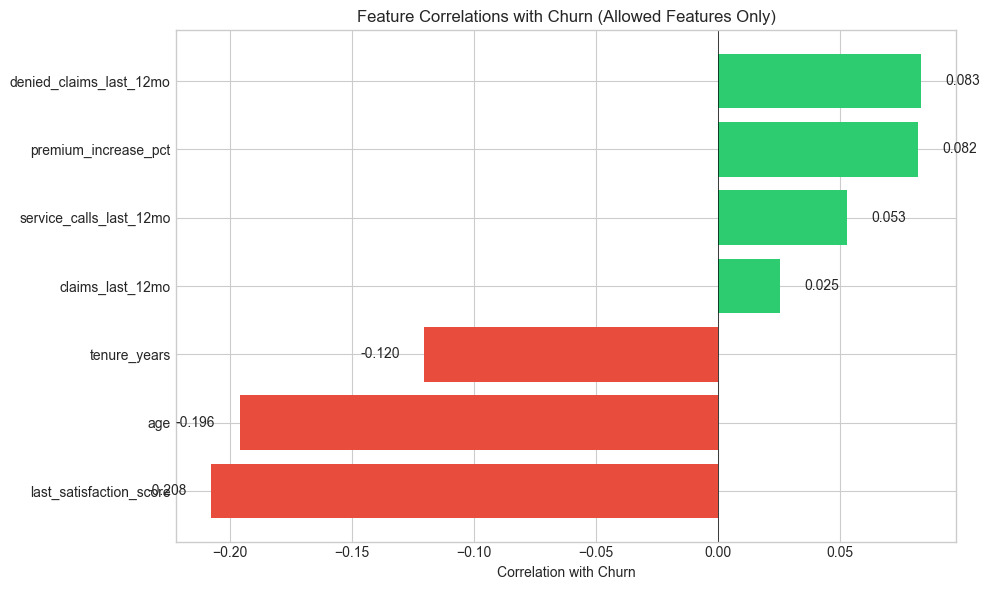


Key observations:
- premium_increase_pct has positive correlation (higher increases -> more churn)
- tenure_years has negative correlation (longer tenure -> less churn)
- last_satisfaction_score has negative correlation (higher satisfaction -> less churn)


In [25]:
# Correlation of allowed numeric features with target
numeric_allowed = ['age', 'tenure_years', 'claims_last_12mo', 'denied_claims_last_12mo', 
                   'premium_increase_pct', 'service_calls_last_12mo', 'last_satisfaction_score']

corr_with_target = train[numeric_allowed + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#e74c3c' if x < 0 else '#2ecc71' for x in corr_with_target.values]
ax.barh(corr_with_target.index, corr_with_target.values, color=colors)
ax.set_xlabel('Correlation with Churn')
ax.set_title('Feature Correlations with Churn (Allowed Features Only)')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)

for i, v in enumerate(corr_with_target.values):
    ax.text(v + 0.01 if v >= 0 else v - 0.01, i, f'{v:.3f}', va='center', ha='left' if v >= 0 else 'right')

plt.tight_layout()
plt.show()

print("\nKey observations:")
print("- premium_increase_pct has positive correlation (higher increases -> more churn)")
print("- tenure_years has negative correlation (longer tenure -> less churn)")
print("- last_satisfaction_score has negative correlation (higher satisfaction -> less churn)")

## 7. Train vs Test Distribution Drift

The data dictionary warns that train (2024) and test (2025) are NOT i.i.d. - there's real distribution shift.

In [26]:
# Compare distributions between train and test
print("Distribution Comparison: Train (2024) vs Test (2025)")
print("="*60)

# Numeric features
print("\nNumeric Features (mean comparison):")
for feat in numeric_features:
    train_mean = train[feat].mean()
    test_mean = test[feat].mean()
    pct_change = (test_mean - train_mean) / train_mean * 100
    print(f"  {feat:30s} Train: {train_mean:8.2f}  Test: {test_mean:8.2f}  Change: {pct_change:+.1f}%")

# Categorical features
print("\nCategorical Features (distribution comparison):")
for feat in ['plan_type', 'state']:
    print(f"\n  {feat}:")
    train_dist = train[feat].value_counts(normalize=True)
    test_dist = test[feat].value_counts(normalize=True)
    for val in train_dist.index:
        train_pct = train_dist.get(val, 0)
        test_pct = test_dist.get(val, 0)
        print(f"    {val:25s} Train: {train_pct:.1%}  Test: {test_pct:.1%}")

Distribution Comparison: Train (2024) vs Test (2025)

Numeric Features (mean comparison):
  age                            Train:    53.04  Test:    53.03  Change: -0.0%
  tenure_years                   Train:     9.09  Test:     9.19  Change: +1.1%
  claims_last_12mo               Train:     5.65  Test:     5.68  Change: +0.6%
  denied_claims_last_12mo        Train:     0.85  Test:     0.85  Change: +0.9%
  premium_increase_pct           Train:     6.55  Test:     6.52  Change: -0.5%
  service_calls_last_12mo        Train:     1.91  Test:     1.93  Change: +0.7%

Categorical Features (distribution comparison):

  plan_type:
    commercial_group          Train: 47.8%  Test: 47.9%
    medicare_advantage        Train: 32.4%  Test: 32.2%
    individual_marketplace    Train: 19.8%  Test: 19.9%

  state:
    OH                        Train: 54.9%  Test: 55.7%
    IN                        Train: 20.3%  Test: 20.0%
    KY                        Train: 15.0%  Test: 14.6%
    WV               

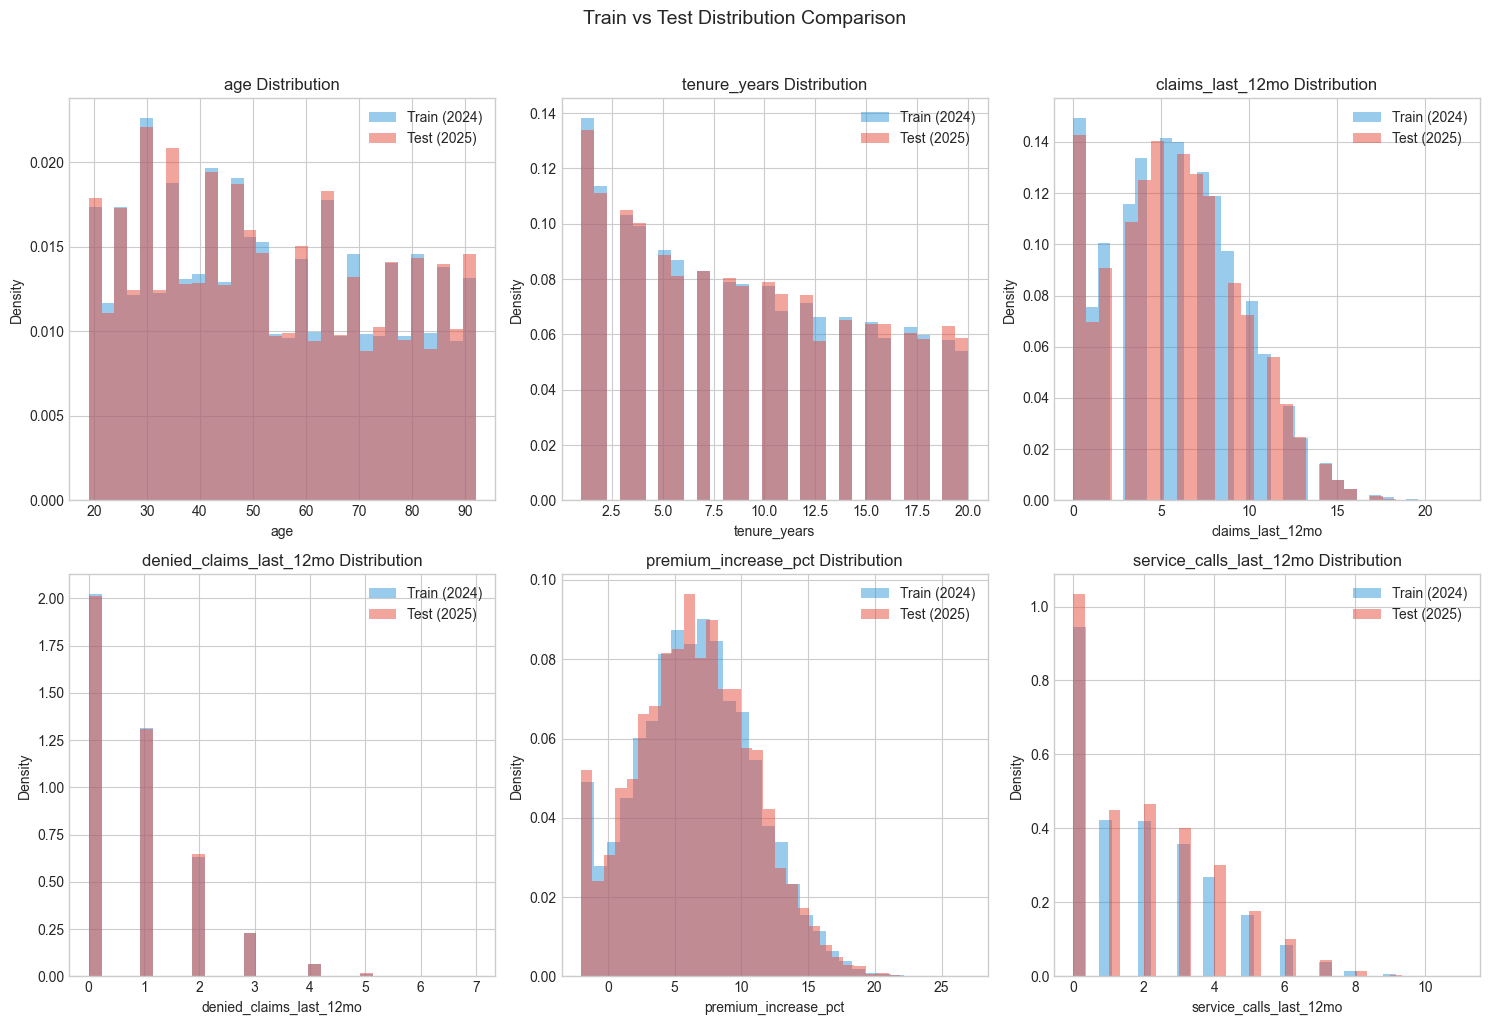

In [27]:
# Visual comparison of key features
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, feat in zip(axes, numeric_features):
    ax.hist(train[feat], bins=30, alpha=0.5, label='Train (2024)', density=True, color='#3498db')
    ax.hist(test[feat], bins=30, alpha=0.5, label='Test (2025)', density=True, color='#e74c3c')
    ax.set_title(f'{feat} Distribution')
    ax.set_xlabel(feat)
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Train vs Test Distribution Comparison', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 8. Blocked Features Analysis (for subgroup reporting only)

These features CANNOT be used for training, but we need to report subgroup performance on them.

In [28]:
# Churn rates by blocked features (for awareness, NOT for modeling)
print("Churn Rates by BLOCKED Features (for subgroup reporting only):")
print("="*60)
print("\n⚠️ These features are BLOCKED from model training per governance policy.")
print("   We analyze them only to understand subgroup performance.\n")

for feat in BLOCKED_FEATURES:
    print(f"\n{feat}:")
    churn_by_feat = train.groupby(feat)['churned'].agg(['mean', 'count'])
    for idx, row in churn_by_feat.iterrows():
        print(f"  {str(idx):30s} Churn: {row['mean']:.1%}  (n={row['count']:,})")

Churn Rates by BLOCKED Features (for subgroup reporting only):

⚠️ These features are BLOCKED from model training per governance policy.
   We analyze them only to understand subgroup performance.


gender:
  F                              Churn: 26.3%  (n=13,317.0)
  M                              Churn: 25.3%  (n=13,279.0)
  X                              Churn: 26.1%  (n=13,404.0)

race:
  asian                          Churn: 25.5%  (n=1,190.0)
  black                          Churn: 25.6%  (n=4,836.0)
  hispanic                       Churn: 25.8%  (n=2,013.0)
  other                          Churn: 29.3%  (n=799.0)
  white                          Churn: 25.9%  (n=31,162.0)

dual_eligible:
  False                          Churn: 27.3%  (n=37,174.0)
  True                           Churn: 7.5%  (n=2,826.0)

mental_health_diagnosis:
  False                          Churn: 26.0%  (n=38,269.0)
  True                           Churn: 24.7%  (n=1,731.0)


## 9. Feature Engineering Ideas

In [29]:
# Potential derived features
print("Potential Feature Engineering Ideas:")
print("="*60)

# 1. Denied claims ratio
train['denied_claims_ratio'] = train['denied_claims_last_12mo'] / (train['claims_last_12mo'] + 1)
print(f"\n1. denied_claims_ratio (denied/total claims):")
print(f"   Correlation with churn: {train['denied_claims_ratio'].corr(train['churned']):.3f}")

# 2. Satisfaction missing indicator
print(f"\n2. satisfaction_missing (binary indicator):")
print(f"   Correlation with churn: {train['satisfaction_missing'].astype(int).corr(train['churned']):.3f}")

# 3. High premium increase flag
train['high_premium_increase'] = (train['premium_increase_pct'] > 10).astype(int)
print(f"\n3. high_premium_increase (>10% increase):")
print(f"   Correlation with churn: {train['high_premium_increase'].corr(train['churned']):.3f}")

# 4. Low tenure flag
train['low_tenure'] = (train['tenure_years'] < 3).astype(int)
print(f"\n4. low_tenure (<3 years):")
print(f"   Correlation with churn: {train['low_tenure'].corr(train['churned']):.3f}")

# 5. Service calls per claim
train['service_calls_per_claim'] = train['service_calls_last_12mo'] / (train['claims_last_12mo'] + 1)
print(f"\n5. service_calls_per_claim:")
print(f"   Correlation with churn: {train['service_calls_per_claim'].corr(train['churned']):.3f}")

Potential Feature Engineering Ideas:

1. denied_claims_ratio (denied/total claims):
   Correlation with churn: 0.062

2. satisfaction_missing (binary indicator):
   Correlation with churn: -0.011

3. high_premium_increase (>10% increase):
   Correlation with churn: 0.086

4. low_tenure (<3 years):
   Correlation with churn: 0.150

5. service_calls_per_claim:
   Correlation with churn: 0.038


## 10. Summary & Key Takeaways

In [30]:
print("""
================================================================================
EDA SUMMARY & KEY TAKEAWAYS
================================================================================

1. TARGET VARIABLE:
   - Train churn rate: ~26%, Test churn rate: ~30%
   - Class imbalance exists but not extreme - no need for SMOTE
   - Churn rate increased from 2024 to 2025 (distribution shift!)

2. LEAKAGE FEATURES (DO NOT USE):
   ✗ cancellation_form_started - directly leaks the outcome
   ✗ days_to_renewal_decision - computed post-outcome
   
3. BLOCKED FEATURES (DO NOT USE FOR TRAINING):
   ✗ gender, race, dual_eligible, mental_health_diagnosis
   ✓ Must report subgroup performance on these

4. KEY PREDICTIVE SIGNALS:
   - premium_increase_pct: Higher increases -> more churn
   - tenure_years: Longer tenure -> less churn  
   - last_satisfaction_score: Higher satisfaction -> less churn
   - satisfaction_missing: Missing score is HIGHLY predictive of churn!
   - plan_type: individual_marketplace has highest churn

5. MISSINGNESS:
   - last_satisfaction_score: ~38% missing
   - Missingness is INFORMATIVE - create binary indicator feature
   - Members who don't respond to surveys churn at much higher rates

6. DISTRIBUTION DRIFT:
   - Train (2024) and Test (2025) have different distributions
   - Churn rate is higher in test set
   - Cross-validation on train alone will be optimistic

7. FEATURE ENGINEERING IDEAS:
   - denied_claims_ratio = denied_claims / (total_claims + 1)
   - satisfaction_missing = binary indicator
   - high_premium_increase = premium_increase_pct > 10%
   - low_tenure = tenure_years < 3

8. EVALUATION STRATEGY:
   - Primary metric: Precision at top 10% (matches business constraint)
   - Must report subgroup performance by plan_type
   - Include calibration curve
   - Be aware of train/test drift when interpreting results
""")


EDA SUMMARY & KEY TAKEAWAYS

1. TARGET VARIABLE:
   - Train churn rate: ~26%, Test churn rate: ~30%
   - Class imbalance exists but not extreme - no need for SMOTE
   - Churn rate increased from 2024 to 2025 (distribution shift!)

2. LEAKAGE FEATURES (DO NOT USE):
   ✗ cancellation_form_started - directly leaks the outcome
   ✗ days_to_renewal_decision - computed post-outcome
   
3. BLOCKED FEATURES (DO NOT USE FOR TRAINING):
   ✗ gender, race, dual_eligible, mental_health_diagnosis
   ✓ Must report subgroup performance on these

4. KEY PREDICTIVE SIGNALS:
   - premium_increase_pct: Higher increases -> more churn
   - tenure_years: Longer tenure -> less churn  
   - last_satisfaction_score: Higher satisfaction -> less churn
   - satisfaction_missing: Missing score is HIGHLY predictive of churn!
   - plan_type: individual_marketplace has highest churn

5. MISSINGNESS:
   - last_satisfaction_score: ~38% missing
   - Missingness is INFORMATIVE - create binary indicator feature
   - Membe